[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)

[![VGI](assets/vgi-logo.png)](https://query.farm/vgi/)

# Adjustment depends on what the model can see

Can adjustment recover a known treatment effect when treatment and outcomes share common causes? We construct a synthetic cohort, fit propensity scores and three treatment-effect estimators through the real causal worker, then inspect covariate balance and the resulting estimates. The final experiment hides one confounder from both models while keeping the cohort fixed.

**All observations are synthetic.** Subjects have anonymous integer IDs, two dimensionless covariates, a binary intervention and an outcome in arbitrary units. The planted effect is **+3 outcome units for every subject**. This is a model demonstration, not evidence about a real treatment, product or population.

## Choose what the estimator observes

`ADJUST_FOR_X2 = True` supplies both known confounders. Setting it to `False` supplies only `x1`; `x2` remains available solely for the simulation audit. `N_SUBJECTS` is an integer from 500 to 10,000; `SEED` is an integer from 0 to 1,000,000. Keep both fixed for the final experiment. Restart and run all after editing parameters.

In [1]:
ADJUST_FOR_X2 = True  # experiment: change only this to False
N_SUBJECTS = 4000  # synthetic subjects; 500–10,000
SEED = 7  # exogenous random draws; integer 0–1,000,000

In [2]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from notebook_support import finish, prose, theme

if type(ADJUST_FOR_X2) is not bool:
    raise ValueError("ADJUST_FOR_X2 must be True or False.")
if type(N_SUBJECTS) is not int or not 500 <= N_SUBJECTS <= 10000:
    raise ValueError("N_SUBJECTS must be an integer from 500 to 10,000.")
if type(SEED) is not int or not 0 <= SEED <= 1000000:
    raise ValueError("SEED must be an integer from 0 to 1,000,000.")
rng = np.random.default_rng(SEED)
exogenous = pd.DataFrame(
    {
        "id": np.arange(N_SUBJECTS, dtype=np.int64),
        "x1": rng.normal(size=N_SUBJECTS),
        "x2": rng.normal(size=N_SUBJECTS),
        "assignment_draw": rng.uniform(size=N_SUBJECTS),
        "noise": rng.normal(size=N_SUBJECTS),
    }
)
model_label = "x1 + x2" if ADJUST_FOR_X2 else "x1 only (x2 omitted)"
run_label = "both" if ADJUST_FOR_X2 else "omit-x2"
theme()
connection = haybarn.connect()
connection.register("input_draws", exogenous)
connection.execute("CREATE TABLE exogenous_draws AS SELECT * FROM input_draws")
connection.unregister("input_draws")
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-causal/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-causal/notebooks/pyproject.toml.

## Attach the pinned worker

The literal Git launcher resolves the published worker revision with SDK 0.51.1. The notebook needs no local worker source or root environment. Every model fit below runs through this VGI connection; Python only generates exogenous inputs and presents results.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'causal' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --from git+https://github.com/Query-farm/vgi-causal@9ec727d6f00fe00d105b89a5c2ac05e9bd4f5dc5 vgi-causal-worker'
);

,Success


## Plant a known effect and confounding

Independent standard-normal `x1`, `x2` and noise, plus an independent uniform assignment draw, come from the fixed NumPy seed. SQL makes treatment more likely when either covariate is large. Both also increase the untreated outcome `y0`. Observed outcome is `y0 + 3 × treatment`, so the individual and average effects are exactly 3 by construction.

Because assignment uses only the two observed covariates and independent randomness, this simulation satisfies no unmeasured confounding **when both covariates are supplied**. Its logistic assignment has theoretical positivity, although finite samples can have poor overlap. Treatment is well defined and subjects do not affect one another. In real data these assumptions require substantive justification; the worker cannot verify them.

In [4]:
%%sql
CREATE TABLE cohort AS
WITH latent AS (
    SELECT *, 1.0 / (1.0 + exp(-(1.2 * x1 + 0.8 * x2))) AS true_propensity,
           2.0 * x1 + 1.5 * x2 + noise AS y0
    FROM exogenous_draws
), assigned AS (
    SELECT *, CAST(assignment_draw < true_propensity AS INTEGER) AS treatment
    FROM latent
)
SELECT id, x1, x2, true_propensity, treatment, y0, y0 + 3.0 * treatment AS outcome
FROM assigned;

SELECT treatment, count(*) AS subjects, avg(x1) AS mean_x1, avg(x2) AS mean_x2,
       avg(outcome) AS mean_outcome
FROM cohort GROUP BY treatment ORDER BY treatment;

,treatment,subjects,mean_x1,mean_x2,mean_outcome
0,0,2037,-0.439459,-0.301942,-1.348810
1,1,1963,0.420159,0.273668,4.295899


## Fit propensity scores using the selected covariates

The visible conditional projection includes `x2` only when requested. Every non-role column is a covariate: `id` is explicitly excluded through the `id` role, and outcome, true propensity and potential outcomes are never passed to this fit. The worker uses regularized logistic regression and clips fitted probabilities to `[10⁻⁶, 1−10⁻⁶]`. Clipping keeps weights finite; it does not establish adequate overlap.

In [5]:
%%sql
CREATE TABLE fitted_scores AS
SELECT * FROM causal.main.propensity_scores(
    (SELECT id, treatment, x1 {{ ', x2' if ADJUST_FOR_X2 else '' }} FROM cohort),
    treatment := 'treatment', id := 'id', random_state := 0
);

CREATE TABLE scored AS
SELECT c.*, p.propensity,
       CASE WHEN c.treatment = 1 THEN 1.0 / p.propensity
            ELSE 1.0 / (1.0 - p.propensity) END AS ipw_weight
FROM cohort c JOIN fitted_scores p USING (id);

SELECT treatment, count(*) AS subjects,
       min(propensity) AS minimum_fitted_p, max(propensity) AS maximum_fitted_p,
       max(ipw_weight) AS maximum_weight,
       pow(sum(ipw_weight), 2) / sum(pow(ipw_weight, 2)) AS effective_sample_size
FROM scored GROUP BY treatment ORDER BY treatment;

,treatment,subjects,minimum_fitted_p,maximum_fitted_p,maximum_weight,effective_sample_size
0,0,2037,0.004414,0.962217,26.466815,1168.882043
1,1,1963,0.033624,0.993653,29.740258,1160.781171


## Audit covariate balance

Compare treated-minus-control standardized mean differences before and after inverse-probability weighting. Weighted means are normalized separately within each arm, matching the worker’s Hájek IPW contrast. The denominator stays the **unweighted pooled within-arm standard deviation** in both comparisons. Effective sample size above summarizes weight concentration; it is not the number of independent subjects magically created by weighting.

The balance audit deliberately includes `x2` even when the model omits it. In an actual study, a truly unmeasured confounder would be unavailable for this audit. Small mean differences are useful diagnostics, but they cannot prove that all confounding has been removed.

In [6]:
%%sql
CREATE TABLE balance AS
WITH long AS (
    SELECT treatment, ipw_weight, 'x1' AS covariate, x1 AS value FROM scored
    UNION ALL
    SELECT treatment, ipw_weight, 'x2' AS covariate, x2 AS value FROM scored
), arms AS (
    SELECT covariate, treatment, avg(value) AS raw_mean, var_samp(value) AS raw_variance,
           sum(ipw_weight * value) / sum(ipw_weight) AS weighted_mean
    FROM long GROUP BY covariate, treatment
)
SELECT t.covariate,
       (t.raw_mean - c.raw_mean) / sqrt((t.raw_variance + c.raw_variance) / 2.0) AS unweighted_smd,
       (t.weighted_mean - c.weighted_mean) / sqrt((t.raw_variance + c.raw_variance) / 2.0) AS weighted_smd
FROM arms t JOIN arms c USING (covariate)
WHERE t.treatment = 1 AND c.treatment = 0;

SELECT * FROM balance ORDER BY covariate;

,covariate,unweighted_smd,weighted_smd
0,x1,0.961644,0.024242
1,x2,0.612412,0.036720


In [7]:
%%sql balance_frame <<
SELECT * FROM balance ORDER BY covariate;

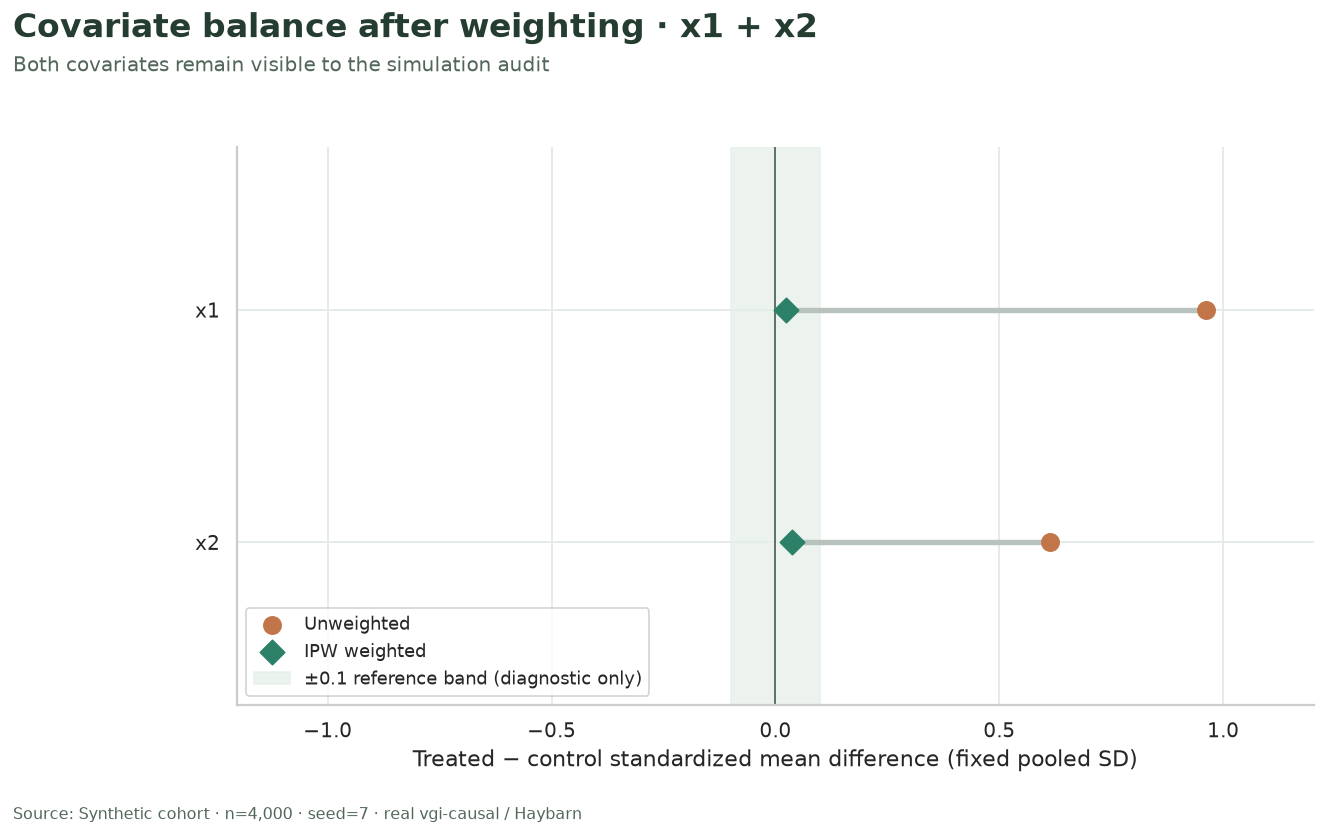

In [8]:
fig, ax = plt.subplots(figsize=(11.5, 6.5))
y = np.arange(len(balance_frame))
for i, row in balance_frame.iterrows():
    ax.plot([row.unweighted_smd, row.weighted_smd], [i, i], color="#b8c3bd", linewidth=3)
ax.scatter(balance_frame.unweighted_smd, y, s=90, color="#c27548", label="Unweighted", zorder=3)
ax.scatter(balance_frame.weighted_smd, y, s=90, color="#2b8067", marker="D", label="IPW weighted", zorder=3)
ax.axvline(0, color="#52675a", linewidth=1)
ax.axvspan(-0.1, 0.1, color="#e5eee8", alpha=0.7, label="±0.1 reference band (diagnostic only)")
limit = max(0.3, float(np.abs(balance_frame[["unweighted_smd", "weighted_smd"]]).max().max()) * 1.25)
ax.set(
    xlim=(-limit, limit),
    ylim=(1.7, -0.7),
    yticks=y,
    yticklabels=balance_frame.covariate,
    xlabel="Treated − control standardized mean difference (fixed pooled SD)",
)
ax.legend(loc="lower left", fontsize=10)
finish(
    fig,
    f"Covariate balance after weighting · {model_label}",
    "Both covariates remain visible to the simulation audit",
    f"balance-{run_label}.png",
    f"Synthetic cohort · n={N_SUBJECTS:,} · seed={SEED} · real vgi-causal / Haybarn",
)

## Compare the estimates against the planted effect

The unadjusted contrast subtracts the control mean outcome from the treated mean. The worker then fits IPW, linear regression adjustment and augmented IPW (AIPW) using the same chosen covariates. The ATE input deliberately excludes `id` and every simulation-only column. Calls are materialized once before display.

AIPW combines propensity and outcome models. Its double-robustness property concerns correct model specification under identification assumptions; it does **not** protect against an omitted common cause that invalidates those assumptions. Intervals below are the worker’s reported 95% Wald intervals; the unadjusted interval uses an independent-arm normal approximation. None accounts for omitted-variable bias.

In [9]:
%%sql
CREATE TABLE adjusted AS
SELECT * FROM causal.main.ate(
    (SELECT treatment, outcome, x1 {{ ', x2' if ADJUST_FOR_X2 else '' }} FROM cohort),
    treatment := 'treatment', outcome := 'outcome', random_state := 0
);

CREATE TABLE estimates AS
WITH arms AS (
    SELECT treatment, count(*) AS n, avg(outcome) AS mean_y, var_samp(outcome) AS variance_y
    FROM cohort GROUP BY treatment
), raw AS (
    SELECT t.mean_y - c.mean_y AS estimate,
           sqrt(t.variance_y / t.n + c.variance_y / c.n) AS std_error
    FROM arms t CROSS JOIN arms c WHERE t.treatment = 1 AND c.treatment = 0
)
SELECT 'unadjusted' AS method, estimate, std_error,
       estimate - 1.959963984540054 * std_error AS ci_lower,
       estimate + 1.959963984540054 * std_error AS ci_upper
FROM raw
UNION ALL SELECT method, estimate, std_error, ci_lower, ci_upper FROM adjusted;

,Count


In [10]:
%%sql results <<
SELECT method, estimate, std_error, ci_lower, ci_upper, estimate - 3.0 AS error_from_truth
FROM estimates
ORDER BY CASE method WHEN 'unadjusted' THEN 0 WHEN 'ipw' THEN 1
                     WHEN 'regression_adjustment' THEN 2 ELSE 3 END;

In [11]:
display(results)

,method,estimate,std_error,ci_lower,ci_upper,error_from_truth
0,unadjusted,5.644709,0.072740,5.502141,5.787276,2.644709
1,ipw,3.177571,0.139051,2.905036,3.450106,0.177571
2,regression_adjustment,3.099143,0.036861,3.026896,3.171389,0.099143
3,aipw,3.084394,0.042245,3.001595,3.167192,0.084394


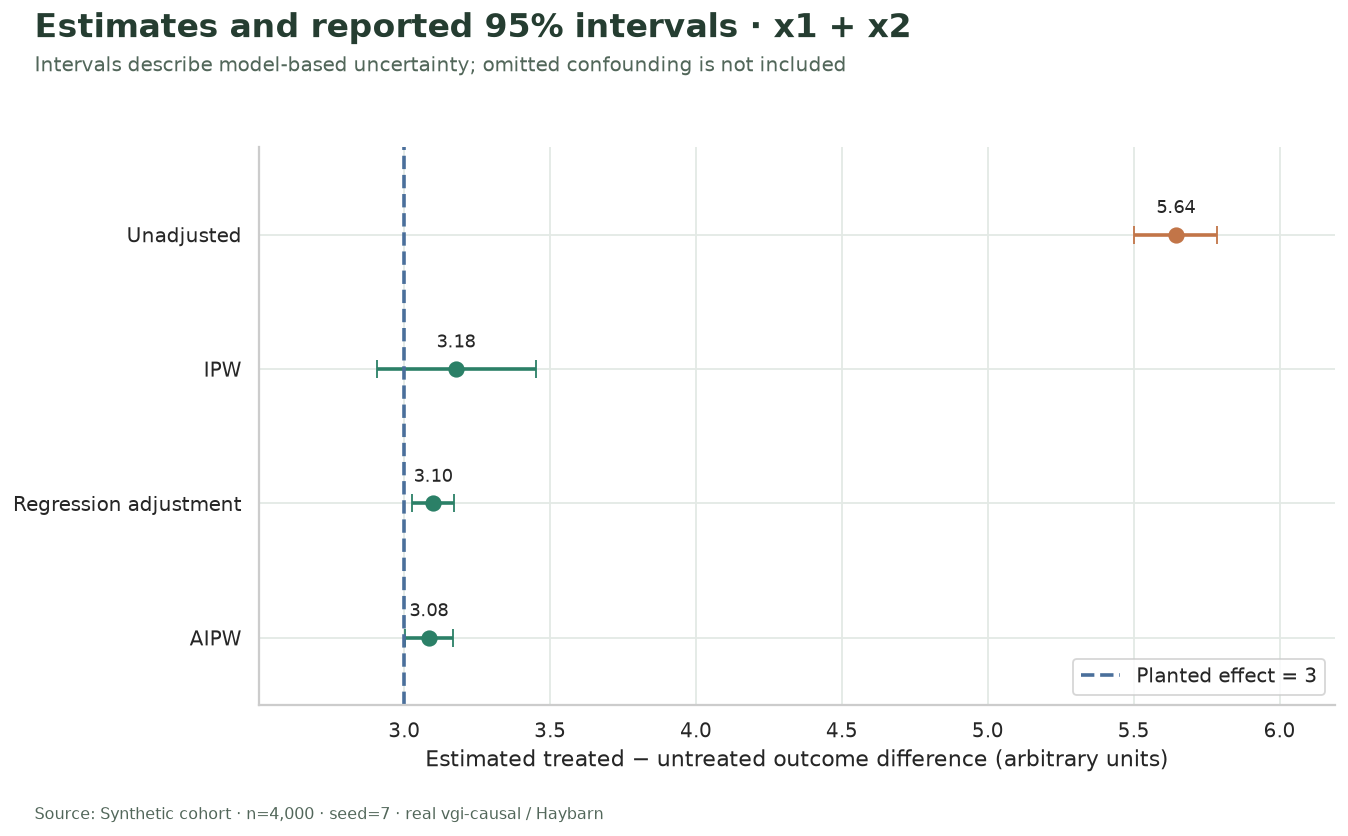

In [12]:
labels = {"unadjusted": "Unadjusted", "ipw": "IPW", "regression_adjustment": "Regression adjustment", "aipw": "AIPW"}
fig, ax = plt.subplots(figsize=(11.5, 6.5))
for i, row in results.iterrows():
    color = "#c27548" if row.method == "unadjusted" else "#2b8067"
    ax.errorbar(
        row.estimate,
        i,
        xerr=[[row.estimate - row.ci_lower], [row.ci_upper - row.estimate]],
        fmt="o",
        color=color,
        markersize=8,
        capsize=5,
        linewidth=2,
    )
    ax.annotate(
        f"{row.estimate:.2f}", (row.estimate, i), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=10
    )
ax.axvline(3.0, color="#4a6f9b", linestyle="--", linewidth=2, label="Planted effect = 3")
left = min(3.0, results.ci_lower.min())
right = max(3.0, results.ci_upper.max())
pad = max(0.2, (right - left) * 0.14)
ax.set(
    xlim=(left - pad, right + pad),
    ylim=(len(results) - 0.5, -0.65),
    yticks=np.arange(len(results)),
    yticklabels=[labels[x] for x in results.method],
    xlabel="Estimated treated − untreated outcome difference (arbitrary units)",
)
ax.legend(loc="lower right")
finish(
    fig,
    f"Estimates and reported 95% intervals · {model_label}",
    "Intervals describe model-based uncertainty; omitted confounding is not included",
    f"effects-{run_label}.png",
    f"Synthetic cohort · n={N_SUBJECTS:,} · seed={SEED} · real vgi-causal / Haybarn",
)

In [13]:
indexed = results.set_index("method")
b = balance_frame.set_index("covariate")
prose(
    f"With **{model_label}**, the unadjusted difference is **{indexed.loc['unadjusted', 'estimate']:.3f}**, "
    f"while AIPW estimates **{indexed.loc['aipw', 'estimate']:.3f}** against the planted effect **3.000**. "
    f"Its error from that known truth is **{indexed.loc['aipw', 'error_from_truth']:+.3f} outcome units**. "
    f"The weighted x2 mean difference is **{b.loc['x2', 'weighted_smd']:+.3f} pooled SDs**."
)
if ADJUST_FOR_X2:
    prose(
        "Both common causes are supplied, and the linear outcome model matches this simulation. "
        "Remaining error reflects this finite sample and the fitted estimators; "
        "recovery here is not validation on real data."
    )
else:
    prose(
        "x2 still drives both treatment and outcome, but neither fitted model receives it. "
        "The supplied adjustment set therefore fails the simulation’s no-unmeasured-confounding requirement. "
        "The software can return precise-looking adjusted associations without recovering the planted causal effect."
    )

With **x1 + x2**, the unadjusted difference is **5.645**, while AIPW estimates **3.084** against the planted effect **3.000**. Its error from that known truth is **+0.084 outcome units**. The weighted x2 mean difference is **+0.037 pooled SDs**.

Both common causes are supplied, and the linear outcome model matches this simulation. Remaining error reflects this finite sample and the fitted estimators; recovery here is not validation on real data.

## Verify the data flow and numerical relationships

These checks test the construction, one-score-per-subject join, valid fitted probabilities, effective sample-size bounds and interval ordering. No assertion demands that a noisy estimate equal the planted effect or that its interval contain it.

In [14]:
%%sql checks <<
SELECT 'planted individual effect', max(abs(outcome - y0 - 3.0 * treatment)) < 1e-10 AS passed FROM cohort
UNION ALL
SELECT 'one score per subject', count(*) = {{N_SUBJECTS}} AND count(DISTINCT id) = {{N_SUBJECTS}} FROM fitted_scores
UNION ALL
SELECT 'joined population preserved', count(*) = {{N_SUBJECTS}} AND count(DISTINCT id) = {{N_SUBJECTS}} FROM scored
UNION ALL
SELECT 'strictly positive fitted probabilities', bool_and(propensity > 0 AND propensity < 1) FROM fitted_scores
UNION ALL
SELECT 'finite estimates and ordered intervals',
       bool_and(isfinite(estimate) AND isfinite(std_error) AND std_error >= 0
                AND ci_lower <= estimate AND estimate <= ci_upper) FROM estimates
UNION ALL
SELECT 'effective sample size bounded', bool_and(ess > 0 AND ess <= n + 1e-8)
FROM (SELECT count(*) AS n, pow(sum(ipw_weight), 2) / sum(pow(ipw_weight, 2)) AS ess
      FROM scored GROUP BY treatment);

In [15]:
display(checks)
assert checks.passed.all(), "A data-flow or numerical invariant failed."

,'planted individual effect',passed
0,planted individual effect,True
1,one score per subject,True
2,joined population preserved,True
3,strictly positive fitted probabilities,True
4,finite estimates and ordered intervals,True
5,effective sample size bounded,True


## Experiment: omit a known confounder

Change only **`ADJUST_FOR_X2` from `True` to `False`** and run all. Keep `N_SUBJECTS = 4000` and `SEED = 7`, so the generated cohort, planted effect and unadjusted contrast remain identical. Predict that `x1` may look balanced while `x2` retains a mean gap, and that adjusted estimates can move away from 3 despite their reported intervals. Compare the balance plot, estimate table and effect plot.

The prediction follows this simulation’s known structure; one finite sample need not give a universal estimator ranking. Agreement among methods also cannot prove identification. In real work, choose covariates using knowledge of how treatment and outcomes arise, not solely whichever estimate looks convincing. Reset **`ADJUST_FOR_X2 = True`**. The README shows how to save this experiment separately.

In [16]:
connection.close()

[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)